# Model Training

## Importing the Data Set

The code below runs the code in the previous notebook, which had all of the data preprocessing steps. This allows one to use variables and functions defined in the code of another notebook. 

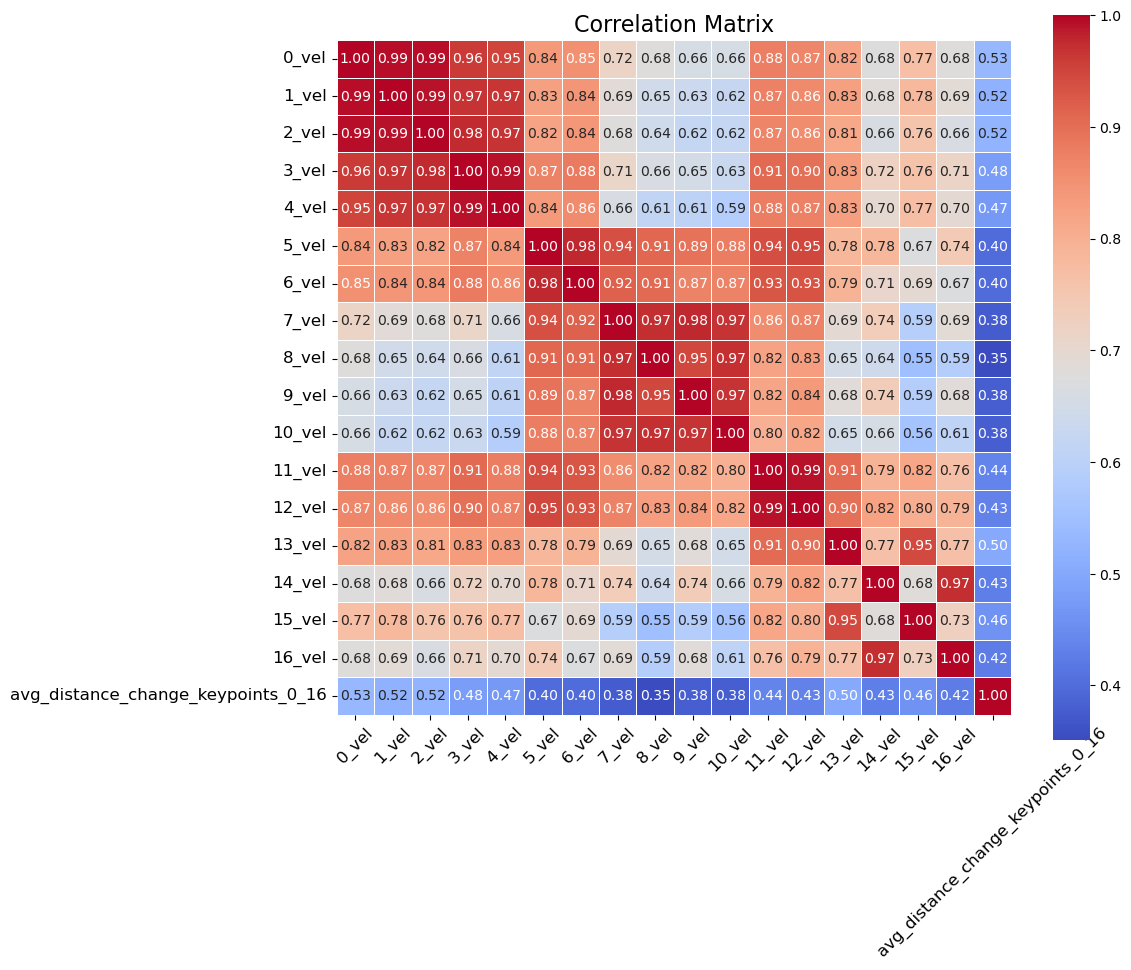

In [1]:
%run 02_data_preprocessing.ipynb

## Training the Model

The below code splits the data into training and testing sets. The training set will be 80% of the data and the testing set will be the other 20%. This section also changes the labels into integers and makes sure the X data and y labels are the same length.

In [2]:
import numpy as np
from sklearn.model_selection import train_test_split

X = df_new  # Features 
y = df['label']    

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

y_train_binary = (y_train == "house").astype(int)  # Binary encoding for training labels
y_test_binary = (y_test == "house").astype(int)    # Binary encoding for testing labels

# Check lengths to ensure they match
assert len(X_train) == len(y_train_binary), f"Length mismatch: {len(X_train)} vs {len(y_train)}"
assert len(X_test) == len(y_test_binary), f"Length mismatch: {len(X_test)} vs {len(y_test)}"


### Classifiers

First, without modification to the features, I will run various classifiers on the data to see which provide the most accurate results. The different models I am testing are logistic regression, support vector machines, K-nearest neighbors, decision tree classification, and random forest classification. I am trying pretty standard parameters first and then will adjust them as I attempt to find the best fit model.

In [3]:
# Fit the classifier (e.g., SGDClassifier)
from sklearn.linear_model import SGDClassifier
import time

# Initialize the classifier
SGD_clf = SGDClassifier(max_iter=1000, tol=1e-3, random_state=42)

# Start the timer
start_time = time.time()

# Fit the model
SGD_clf.fit(X_train, y_train)

# Stop the timer
end_time = time.time()

# Calculate elapsed time
training_time = end_time - start_time
print(f"Training Time: {training_time:.4f} seconds")

# Make predictions on the test set
y_pred_sgd = SGD_clf.predict(X_test)



Training Time: 0.0022 seconds


In [4]:
from sklearn.linear_model import LogisticRegression

# Initialize the classifier
log_reg = LogisticRegression(max_iter=1000, random_state=42)

start_time = time.time()

# Fit the model
log_reg.fit(X_train, y_train)

end_time = time.time()
training_time = end_time - start_time
print(f"Training Time: {training_time:.4f} seconds")

# Make predictions
y_pred_log = log_reg.predict(X_test)

Training Time: 0.0156 seconds


In [5]:
from sklearn.svm import SVC

# Initialize the classifier
svm_clf = SVC(kernel='linear', random_state=42)

start_time = time.time()

# Fit the model
svm_clf.fit(X_train, y_train)

end_time = time.time()
training_time = end_time - start_time
print(f"Training Time: {training_time:.4f} seconds")

# Make predictions
y_pred_svm = svm_clf.predict(X_test)

Training Time: 0.0353 seconds


In [6]:
from sklearn.neighbors import KNeighborsClassifier

# Initialize the classifier
knn_clf = KNeighborsClassifier(n_neighbors=5)

start_time = time.time()

# Fit the model
knn_clf.fit(X_train, y_train)

end_time = time.time()
training_time = end_time - start_time
print(f"Training Time: {training_time:.4f} seconds")

# Make predictions
y_pred_knn = knn_clf.predict(X_test)

Training Time: 0.0013 seconds


In [7]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the classifier
dt_clf = DecisionTreeClassifier(random_state=42)

start_time = time.time()

# Fit the model
dt_clf.fit(X_train, y_train)

end_time = time.time()
training_time = end_time - start_time
print(f"Training Time: {training_time:.4f} seconds")

# Make predictions
y_pred_dt = dt_clf.predict(X_test)

Training Time: 0.0046 seconds


In [8]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the classifier
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)

start_time = time.time()

# Fit the model
rf_clf.fit(X_train, y_train)

end_time = time.time()
training_time = end_time - start_time
print(f"Training Time: {training_time:.4f} seconds")

# Make predictions
y_pred_rf = rf_clf.predict(X_test)

Training Time: 0.1260 seconds


### Plotting Learning Curves

Learning curves show how well a model is doing as the number of samples increase. They also help us identify if a model is underfitting or overfitting, so they are a good tool to use when training models.

In [9]:
from sklearn.model_selection import learning_curve
def plot_learning_curves(clf, X, y, ax, name, train_sizes=np.linspace(0.1, 1.0, 10), cv=5, scoring='accuracy'):
    """
    Plot learning curves for a given classifier.

    Parameters:
    - clf: The classifier model.
    - X: Feature matrix.
    - y: Target vector.
    - ax: The axis object for plotting (to plot on the subplot).
    - name: The name of the classifier (for title).
    - train_sizes: Proportion of training data to use (default: 10 evenly spaced).
    - cv: Number of cross-validation folds (default: 5).
    - scoring: Scoring metric (default: accuracy).
    """
    # Calculate learning curves
    train_sizes, train_scores, validation_scores = learning_curve(
        clf, X, y, train_sizes=train_sizes, cv=cv, scoring=scoring, n_jobs=-1
    )
    
    # Calculate mean and std for training and validation scores
    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    validation_scores_mean = np.mean(validation_scores, axis=1)
    validation_scores_std = np.std(validation_scores, axis=1)
    
    # Plot learning curves for this classifier
    ax.plot(train_sizes, train_scores_mean, label='Training Score', marker='o')
    ax.fill_between(train_sizes, 
                    train_scores_mean - train_scores_std, 
                    train_scores_mean + train_scores_std, alpha=0.1, color='blue')
    ax.plot(train_sizes, validation_scores_mean, label='Validation Score', marker='o', color='orange')
    ax.fill_between(train_sizes, 
                    validation_scores_mean - validation_scores_std, 
                    validation_scores_mean + validation_scores_std, alpha=0.1, color='orange')

    # Set labels and title for each subplot
    ax.set_title(f'Learning Curves - {name}')
    ax.set_xlabel('Training Set Size')
    ax.set_ylabel('Score')
    ax.legend(loc='best')
    ax.grid(True)


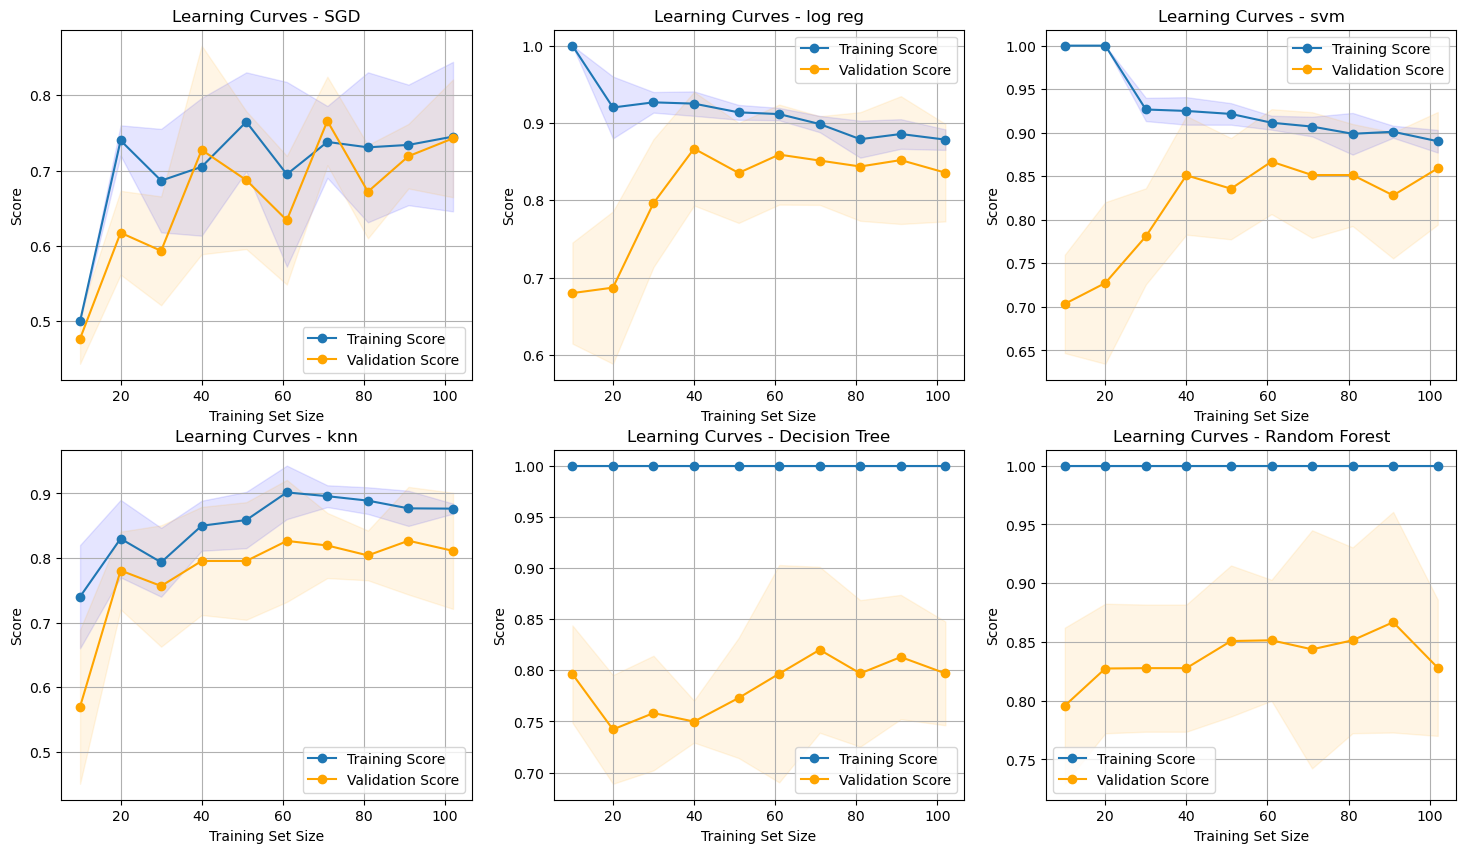

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))  # 2 rows, 3 columns for 6 classifiers
axes = axes.ravel()

plot_learning_curves(SGD_clf, X_train, y_train, axes[0], 'SGD', cv=5)
plot_learning_curves(log_reg, X_train, y_train, axes[1], 'log reg', cv=5)
plot_learning_curves(svm_clf, X_train, y_train, axes[2], 'svm', cv=5)
plot_learning_curves(knn_clf, X_train, y_train, axes[3], 'knn', cv=5)
plot_learning_curves(dt_clf, X_train, y_train, axes[4], 'Decision Tree', cv=5)
plot_learning_curves(rf_clf, X_train, y_train, axes[5], 'Random Forest', cv=5)

Something to look for is a good learning curve should have both training and validation scores increase, converge, and stay close together. The scores should eventually plateau. The KNN, logistic regression, and SVM learning curves are all good fits. The KNN curve fits the description quite well, but plateaus at a slightly lower accuracy. The logistic regression and SVM graphs start at 1, which can be a sign of overfitting, but since the validation score is not low, it seems to just be a sign that the model is fitting perfectly. Overfitting tends to look like a much higher training score than validation score which seems to be the case with the decision tree and random forest graphs. I wouldn't say any of these are underfitting, which is when both scores remain low and do not improve much. While the scores are low for the SGD graph compared to the rest, they do improve a decent amount, so they do not meet the second criteria. 